# Assignment 2: training pipeline 


## 0. Setup


In [1]:
import importlib.util
import os
import subprocess
import sys

# google.colab is only installed on Colab machines; the extra checks cover runtimes that don't preload it
IN_COLAB = (importlib.util.find_spec("google") is not None and importlib.util.find_spec("google.colab") is not None
            or "COLAB_RELEASE_TAG" in os.environ or os.path.isdir("/content/sample_data"))
print("Running on Colab:", IN_COLAB)
REPO_URL = "https://github.com/pilarguerreromorales/daiist-assignment-2.git"

if IN_COLAB:
    repo = "/content/daiist-assignment-2"
    if os.path.isdir(repo):
        subprocess.run(["git", "-C", repo, "pull", "--ff-only"], check=True)
    else:
        subprocess.run(["git", "clone", REPO_URL, repo], check=True)
    os.chdir(repo)
    sys.path.insert(0, repo)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "ultralytics>=8.4,<8.5", "roboflow>=1.7"],
                   check=True)
    if not os.environ.get("ROBOFLOW_API_KEY"):
        from getpass import getpass
        os.environ["ROBOFLOW_API_KEY"] = getpass("Roboflow API key: ")

Running on Colab: False


In [2]:
import json
import os
import shutil
import sys
from pathlib import Path

import matplotlib

IN_NOTEBOOK = "ipykernel" in sys.modules
if not IN_NOTEBOOK:
    matplotlib.use("Agg")  # run via main.py: save figures instead of opening windows

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import yaml
from IPython.display import display
from matplotlib.patches import Rectangle
from PIL import Image
from ultralytics import YOLO

from api_key import load_api_key

ROOT = Path.cwd()
pd.set_option("display.precision", 3)

In [3]:
# Dataset: Roboflow Universe, used as published 
RF_WORKSPACE, RF_PROJECT, RF_VERSION = "joseph-nelson", "hard-hat-workers", 5
DATA_DIR = ROOT / "datasets" / f"{RF_PROJECT}-v{RF_VERSION}"
CLASS_NAMES = ["head", "helmet"]
POSITIVE = "head"  # a worker without a helmet is the event we must catch
SPLITS = ["train", "valid", "test"]

# Training
QUICK = os.environ.get("QUICK") == "1"
# REUSE_WEIGHTS=1 skips training and evaluates the committed weights (trained on a Colab T4,
# settings in outputs/training_config.json), to refresh the evaluation without retraining.
REUSE_WEIGHTS = os.environ.get("REUSE_WEIGHTS") == "1"
BASE_MODEL = "yolo11n.pt"
EPOCHS = 1 if QUICK else 50
PATIENCE = 15
IMGSZ = 640
BATCH = 16
SEED = 0

# Evaluation
DET_CONF = 0.25  
IOU_THRS = np.round(np.arange(0.5, 0.96, 0.05), 2) 
BOX = ["x1", "y1", "x2", "y2"]

if torch.cuda.is_available():
    DEVICE = 0
elif torch.backends.mps.is_available():
    DEVICE = "mps"
else:
    DEVICE = "cpu"

OUT_DIR = ROOT / "runs" / "quick" if QUICK else ROOT / "outputs"
WEIGHTS_DIR = ROOT / "runs" / "quick" if QUICK else ROOT / "weights"
PRETRAINED_DIR = ROOT / "runs" / "pretrained"  # COCO checkpoints, kept out of git
FIG_DIR = OUT_DIR / "figures"
for d in (OUT_DIR, WEIGHTS_DIR, PRETRAINED_DIR, FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)

COLORS = {"head": "tab:red", "helmet": "tab:green"}
print(f"device={DEVICE}  quick={QUICK}  outputs -> {OUT_DIR.relative_to(ROOT)}")

device=mps  quick=False  outputs -> outputs


In [4]:
def save_fig(fig, name):
    """Save every figure so the report and the app can reuse it."""
    fig.savefig(FIG_DIR / f"{name}.png", dpi=120, bbox_inches="tight")
    if IN_NOTEBOOK:
        plt.show()
    else:
        plt.close(fig)


def save_json(obj, name):
    (OUT_DIR / name).write_text(json.dumps(obj, indent=2, default=float))

## 1. Download the dataset

Downloads `joseph-nelson/hard-hat-workers` version 5 (`raw_HeadHelmetClasses`): two
classes and no augmentation, keeping Roboflow's train/valid/test split. If the dataset is
already in `datasets/`, the download is skipped.

In [5]:
if not (DATA_DIR / "data.yaml").exists():
    from roboflow import Roboflow

    rf = Roboflow(api_key=load_api_key())
    rf.workspace(RF_WORKSPACE).project(RF_PROJECT).version(RF_VERSION).download(
        "yolov11", location=str(DATA_DIR)
    )

rf_yaml = yaml.safe_load((DATA_DIR / "data.yaml").read_text())
assert rf_yaml["names"] == CLASS_NAMES, rf_yaml["names"]

# Roboflow's data.yaml uses relative paths that Ultralytics resolves from the wrong folder,
# so write one with an absolute root (kept inside the gitignored datasets/ folder).
DATA_YAML = DATA_DIR / "data_local.yaml"
DATA_YAML.write_text(yaml.safe_dump({
    "path": str(DATA_DIR),
    "train": "train/images",
    "val": "valid/images",
    "test": "test/images",
    "names": dict(enumerate(CLASS_NAMES)),
}))
print(rf_yaml.get("roboflow"))

{'workspace': 'joseph-nelson', 'project': 'hard-hat-workers', 'version': 5, 'license': 'Public Domain', 'url': 'https://universe.roboflow.com/joseph-nelson/hard-hat-workers/dataset/5'}


## 2. Describe the dataset



In [6]:
def read_split(split):
    """One row per box and one row per image for a split, from the YOLO label files."""
    boxes, images = [], []
    for img in sorted((DATA_DIR / split / "images").iterdir()):
        w, h = Image.open(img).size
        label = DATA_DIR / split / "labels" / f"{img.stem}.txt"
        lines = label.read_text().splitlines() if label.exists() else []
        counts = dict.fromkeys(CLASS_NAMES, 0)
        for line in filter(str.strip, lines):
            c, x, y, bw, bh = line.split()
            name = CLASS_NAMES[int(c)]
            counts[name] += 1
            x, y, bw, bh = map(float, (x, y, bw, bh))
            boxes.append(dict(
                split=split, image=img.name, cls=name, img_w=w, img_h=h,
                x1=(x - bw / 2) * w, y1=(y - bh / 2) * h, x2=(x + bw / 2) * w, y2=(y + bh / 2) * h,
                rel_area=bw * bh,
            ))
        images.append(dict(split=split, image=img.name, path=str(img), img_w=w, img_h=h,
                           **{f"n_{c}": n for c, n in counts.items()}))
    return boxes, images


parts = [read_split(s) for s in SPLITS]
gt = pd.DataFrame([b for bx, _ in parts for b in bx])
images = pd.DataFrame([i for _, im in parts for i in im])

# Side length of each box in pixels once the image is letterboxed to IMGSZ for training
scale = IMGSZ / np.maximum(gt.img_w, gt.img_h)
gt["side_px"] = np.sqrt((gt.x2 - gt.x1) * (gt.y2 - gt.y1)) * scale

images["has_head"] = images.n_head > 0
images["composition"] = np.select(
    [images.n_head > 0, images.n_helmet > 0], ["≥1 bare head", "all helmeted"], "no people"
)

Summary of stasts in the dataset

In [7]:
summary = pd.DataFrame({
    "images": images.groupby("split").size(),
    "head boxes": gt[gt.cls == "head"].groupby("split").size(),
    "helmet boxes": gt[gt.cls == "helmet"].groupby("split").size(),
    "images with ≥1 head": images.groupby("split").has_head.sum(),
    "share of images with ≥1 head": images.groupby("split").has_head.mean(),
    "median box area (head)": gt[gt.cls == "head"].groupby("split").rel_area.median(),
    "median box area (helmet)": gt[gt.cls == "helmet"].groupby("split").rel_area.median(),
}).loc[SPLITS]
summary.loc["total"] = summary.sum().where(~summary.columns.str.contains("share|median"))
summary.to_csv(OUT_DIR / "dataset_summary.csv")
display(summary)

,images,head boxes,helmet boxes,images with ≥1 head,share of images with ≥1 head,median box area (head),median box area (helmet)
split,,,,,,,
train,4916.0,4612.0,13919.0,911.0,0.185,0.006,0.008
valid,1413.0,1339.0,3913.0,256.0,0.181,0.006,0.009
test,706.0,726.0,1915.0,140.0,0.198,0.006,0.008
total,7035.0,6677.0,19747.0,1307.0,NaN,NaN,NaN


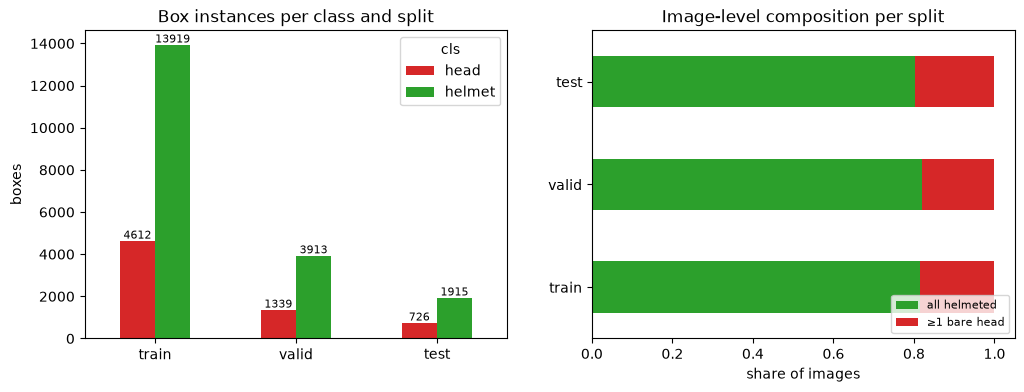

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

inst = gt.groupby(["split", "cls"]).size().unstack().loc[SPLITS]
inst.plot.bar(ax=axes[0], color=[COLORS[c] for c in inst.columns], rot=0)
axes[0].set(title="Box instances per class and split", ylabel="boxes", xlabel="")
for cont in axes[0].containers:
    axes[0].bar_label(cont, fontsize=8)

comp = pd.crosstab(images.split, images.composition, normalize="index").loc[SPLITS]
comp.plot.barh(stacked=True, ax=axes[1], color={"≥1 bare head": "tab:red", "all helmeted": "tab:green",
                                                  "no people": "lightgrey"})
axes[1].set(title="Image-level composition per split", xlabel="share of images", ylabel="")
axes[1].legend(loc="lower right", fontsize=8)
save_fig(fig, "eda_class_balance")

How big is the area of the two different classes? head vs helmet

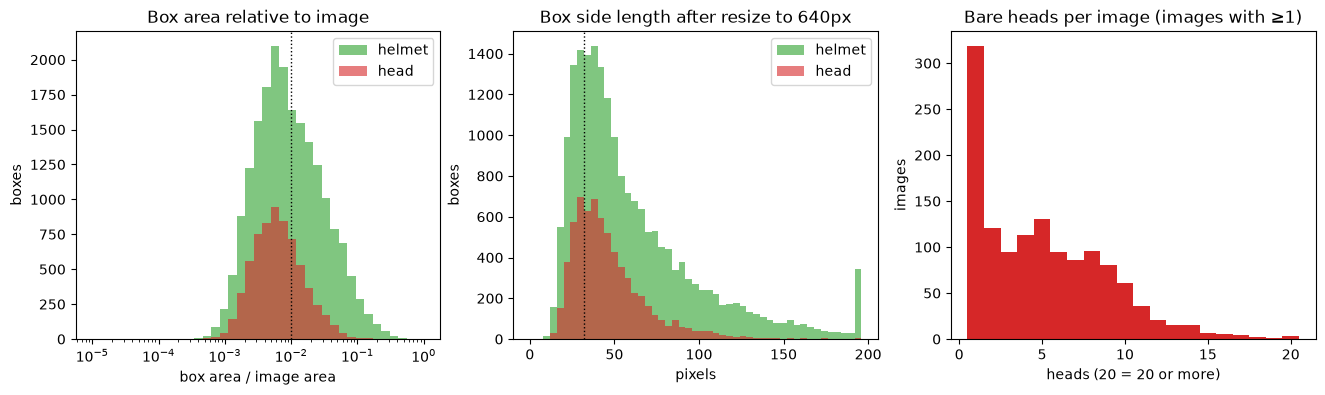

side_px       <16px  16-32px  32-64px  ≥64px
split cls                                   
train head       25     1256     2552    779
      helmet    112     3088     6038   4681
valid head        6      376      739    218
      helmet     55      805     1656   1397
test  head        0      176      436    114
      helmet     11      417      838    649

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

bins = np.logspace(-5, 0, 40)
for c in reversed(CLASS_NAMES):  # helmet first so the smaller head histogram is drawn on top
    axes[0].hist(gt[gt.cls == c].rel_area, bins=bins, alpha=0.6, label=c, color=COLORS[c])
axes[0].set(xscale="log", title="Box area relative to image", xlabel="box area / image area", ylabel="boxes")
axes[0].axvline(0.01, color="k", ls=":", lw=1)
axes[0].legend()

bins = np.arange(0, 200, 4)
for c in reversed(CLASS_NAMES):
    axes[1].hist(gt[gt.cls == c].side_px.clip(upper=196), bins=bins, alpha=0.6, label=c, color=COLORS[c])
axes[1].set(title=f"Box side length after resize to {IMGSZ}px", xlabel="pixels", ylabel="boxes")
axes[1].axvline(32, color="k", ls=":", lw=1)
axes[1].legend()

heads = images[images.has_head].n_head
axes[2].hist(heads.clip(upper=20), bins=np.arange(1, 22) - 0.5, color=COLORS["head"])
axes[2].set(title="Bare heads per image (images with ≥1)", xlabel="heads (20 = 20 or more)", ylabel="images")
save_fig(fig, "eda_object_size")

size_bins = pd.cut(gt.side_px, [0, 16, 32, 64, np.inf], labels=["<16px", "16-32px", "32-64px", "≥64px"])
display(pd.crosstab([gt.split, gt.cls], size_bins).loc[SPLITS])

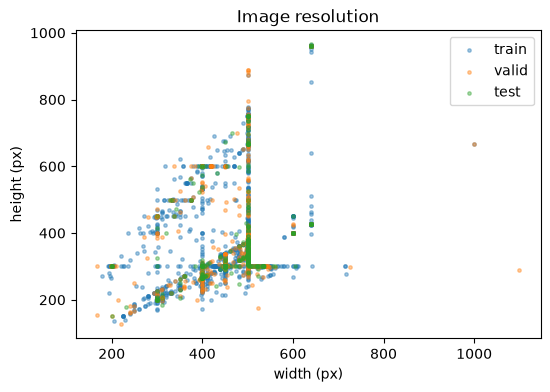

split           train     valid     test
img_w count  4916.000  1413.000  706.000
      mean    476.057   477.784  482.554
      std      65.984    67.387   59.238
      min     179.000   167.000  199.000
      25%     456.750   468.000  500.000
      50%     500.000   500.000  500.000
      75%     500.000   500.000  500.000
      max    1000.000  1100.000  640.000
img_h count  4916.000  1413.000  706.000
      mean    357.802   361.612  357.962
      std     108.339   115.192  106.509
      min     136.000   126.000  151.000
      25%     313.000   312.000  317.000
      50%     333.000   333.000  333.000
      75%     371.000   371.000  366.000
      max     963.000   960.000  965.000

In [10]:
fig, ax = plt.subplots(figsize=(6, 4))
for s in SPLITS:
    d = images[images.split == s]
    ax.scatter(d.img_w, d.img_h, s=6, alpha=0.4, label=s)
ax.set(title="Image resolution", xlabel="width (px)", ylabel="height (px)")
ax.legend()
save_fig(fig, "eda_resolution")
display(images.groupby("split")[["img_w", "img_h"]].describe().loc[SPLITS].T)

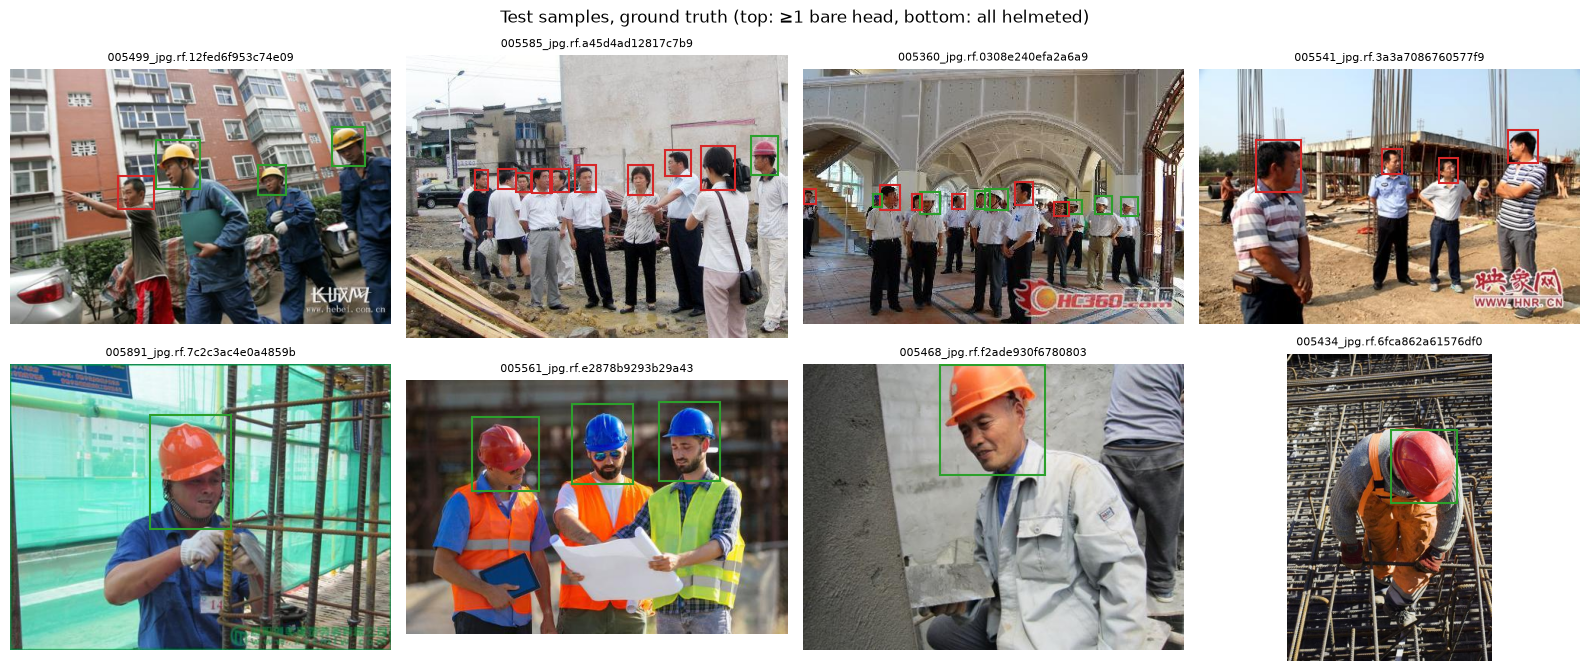

In [11]:
def draw(ax, image_row, truth=None, preds=None, title=None):
    """Image with ground truth (solid) and predictions (dashed, labelled with confidence)."""
    ax.imshow(Image.open(image_row.path))
    for frame, style in ((truth, "-"), (preds, "--")):
        if frame is None:
            continue
        for b in frame[frame.image == image_row.image].itertuples():
            ax.add_patch(Rectangle((b.x1, b.y1), b.x2 - b.x1, b.y2 - b.y1, fill=False,
                                   ec=COLORS[b.cls], lw=1.5, ls=style))
            if style == "--":
                ax.text(b.x1, b.y1, f"{b.conf:.2f}", color="white", fontsize=7,
                        bbox=dict(fc=COLORS[b.cls], ec="none", pad=1))
    ax.set_title(title or image_row.image[:30], fontsize=8)
    ax.axis("off")


def grid(rows, title, name, truth=None, preds=None, titles=None, ncols=4):
    rows = list(rows.itertuples())
    if not rows:
        print(f"{title}: nothing to show")
        return
    nrows = int(np.ceil(len(rows) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 3.4 * nrows), squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for i, (ax, r) in enumerate(zip(axes.flat, rows)):
        draw(ax, r, truth, preds, titles[i] if titles else None)
    fig.suptitle(title)
    fig.tight_layout()
    save_fig(fig, name)


test_imgs = images[images.split == "test"].reset_index(drop=True)
test_gt = gt[gt.split == "test"].reset_index(drop=True)
grid(pd.concat([test_imgs[test_imgs.has_head].sample(4, random_state=SEED),
                test_imgs[~test_imgs.has_head].sample(4, random_state=SEED)]),
     "Test samples, ground truth (top: ≥1 bare head, bottom: all helmeted)", "eda_samples", truth=test_gt)

## 3. Models and baselines 

All three models are scored on the same **test split** with the same matching code: a prediction is correct if it has the right class and IoU ≥ 0.5 with an unused ground-truth box.

| Model | What it is |
|---|---|
| **Finetuned** | `yolo11n` from COCO weights, trained on the train split, best epoch picked on valid |
| **COCO zero-shot** | The same pretrained `yolo11n` with no training. COCO has no head or helmet class, so its `person` boxes are read as `head`, he does not have the helmet class |
| **Predict nothing** | Never flags anything, so every image passes |

In [12]:
def get_pretrained(name):
    """COCO checkpoint stored under runs/ so it never lands in weights/ or the repo root."""
    path = PRETRAINED_DIR / name
    if not path.exists():
        src = Path(YOLO(name).ckpt_path)  # Ultralytics downloads into the working directory
        shutil.copy(src, path)
        if src.resolve().parent == ROOT:
            src.unlink()
    return path


def predict_split(model, split="test", conf=0.001):
    """Every box the model outputs on a split, down to a very low confidence, so thresholds can be swept later."""
    rows = []
    for r in model.predict(str(DATA_DIR / split / "images"), conf=conf, imgsz=IMGSZ, batch=BATCH,
                           device=DEVICE, stream=True, verbose=False):
        name = Path(r.path).name
        for xyxy, c, s in zip(r.boxes.xyxy.tolist(), r.boxes.cls.int().tolist(), r.boxes.conf.tolist()):
            rows.append(dict(image=name, cls=r.names[c], conf=s, **dict(zip(BOX, xyxy))))
    return pd.DataFrame(rows, columns=["image", "cls", "conf", *BOX])

### Finetuning


In [13]:
train_cfg = dict(
    data=str(DATA_YAML), epochs=EPOCHS, patience=PATIENCE, imgsz=IMGSZ, batch=BATCH, seed=SEED,
    device=DEVICE, project=str(ROOT / "runs"), name="quick_train" if QUICK else "hardhat", exist_ok=True,
    fraction=0.05 if QUICK else 1.0, plots=True, verbose=False,
)
WEIGHTS = WEIGHTS_DIR / f"hardhat_{Path(BASE_MODEL).stem}.pt"
REUSING = REUSE_WEIGHTS and WEIGHTS.exists()

if REUSING:
    print(f"REUSE_WEIGHTS=1: evaluating the committed {WEIGHTS.relative_to(ROOT)} without retraining")
    print(json.loads((OUT_DIR / "training_config.json").read_text()))
else:
    model = YOLO(get_pretrained(BASE_MODEL))
    model.train(**train_cfg)
    shutil.copy(model.trainer.best, WEIGHTS)
    shutil.copy(Path(model.trainer.save_dir) / "results.png", FIG_DIR / "training_curves.png")
    save_json({**train_cfg, "base_model": BASE_MODEL, "device": str(DEVICE),
               "torch": torch.__version__, "best_epoch_weights": str(WEIGHTS.relative_to(ROOT))},
              "training_config.json")
    print("saved", WEIGHTS.relative_to(ROOT))

REUSE_WEIGHTS=1: evaluating the committed weights/hardhat_yolo11n.pt without retraining
{'data': '/content/daiist-assignment-2/datasets/hard-hat-workers-v5/data_local.yaml', 'epochs': 50, 'patience': 15, 'imgsz': 640, 'batch': 16, 'seed': 0, 'device': '0', 'project': '/content/daiist-assignment-2/runs', 'name': 'hardhat', 'exist_ok': True, 'fraction': 1.0, 'plots': True, 'verbose': False, 'base_model': 'yolo11n.pt', 'torch': '2.11.0+cu130', 'best_epoch_weights': 'weights/hardhat_yolo11n.pt'}


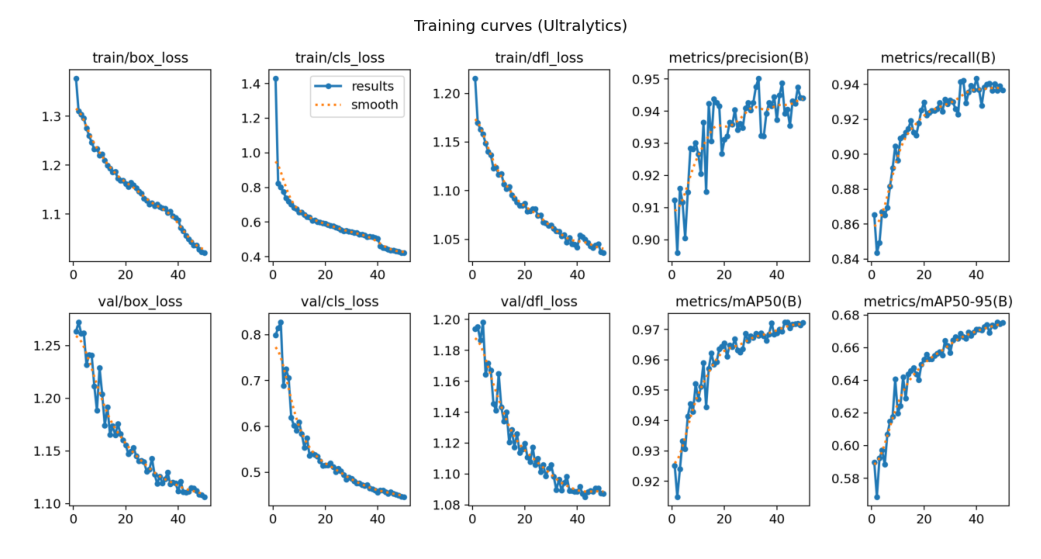

In [14]:
# Ultralytics' loss and metric curves per epoch, copied from the training run
curves = FIG_DIR / "training_curves.png"
if curves.exists():
    fig, ax = plt.subplots(figsize=(14, 7))
    ax.imshow(plt.imread(curves))
    ax.axis("off")
    plt.show() if IN_NOTEBOOK else plt.close(fig)

In [15]:
finetuned = YOLO(WEIGHTS)
coco = YOLO(get_pretrained(BASE_MODEL))

raw_coco = predict_split(coco)
preds = {
    "finetuned": predict_split(finetuned),
    "coco_zero_shot": raw_coco[raw_coco.cls == "person"].assign(cls="head"),
    "predict_nothing": pd.DataFrame(columns=["image", "cls", "conf", *BOX]).astype({"conf": float}),
}
{k: len(v) for k, v in preds.items()}

{'finetuned': 9058, 'coco_zero_shot': 41477, 'predict_nothing': 0}

## 4. Per-class evaluation 

In [16]:
def iou_matrix(a, b):
    tl = np.maximum(a[:, None, :2], b[None, :, :2])
    br = np.minimum(a[:, None, 2:], b[None, :, 2:])
    inter = np.clip(br - tl, 0, None).prod(2)
    area = lambda x: (x[:, 2:] - x[:, :2]).prod(1)
    return inter / (area(a)[:, None] + area(b)[None, :] - inter + 1e-9)


def match_class(p, truth, cls, iou_thr=0.5):
    """Greedy, highest confidence first: each prediction of `cls` takes the best unused
    ground-truth box of `cls` with IoU >= iou_thr. Returns (predictions with a tp flag,
    ground truth with a hit flag)."""
    p = p[p.cls == cls].reset_index(drop=True)
    g = truth[truth.cls == cls].reset_index(drop=True)
    tp, hit = np.zeros(len(p), bool), np.zeros(len(g), bool)
    g_idx = g.groupby("image").groups
    for img, d in p.groupby("image"):
        if img not in g_idx:
            continue
        gi = np.asarray(g_idx[img])
        d = d.sort_values("conf", ascending=False)
        ious = iou_matrix(d[BOX].to_numpy(), g.loc[gi, BOX].to_numpy())
        for row, iou in zip(d.index, ious):
            iou = np.where(hit[gi], 0.0, iou)
            j = iou.argmax()
            if iou[j] >= iou_thr:
                hit[gi[j]] = tp[row] = True
    return p.assign(tp=tp), g.assign(hit=hit)


def average_precision(tp, conf, n_gt):
    """Area under the interpolated precision-recall curve (101-point, as in COCO)."""
    if n_gt == 0:
        return np.nan
    if len(tp) == 0:
        return 0.0
    tp = tp[np.argsort(-conf)]
    ctp, cfp = np.cumsum(tp), np.cumsum(~tp)
    recall = np.concatenate([[0], ctp / n_gt, [1]])
    precision = np.concatenate([[1], ctp / (ctp + cfp), [0]])
    precision = np.flip(np.maximum.accumulate(np.flip(precision)))
    x = np.linspace(0, 1, 101)
    return np.trapezoid(np.interp(x, recall, precision), x)


def per_class(p, truth, conf=DET_CONF):
    rows = []
    for c in CLASS_NAMES:
        aps = []
        for t in IOU_THRS:
            m, g = match_class(p, truth, c, t)
            aps.append(average_precision(m.tp.to_numpy(), m.conf.to_numpy(), len(g)))
            if t == 0.5:
                kept = m[m.conf >= conf]
                tp50 = kept.tp.sum()
                rows.append(dict(cls=c, instances=len(g), predictions=len(kept),
                                 precision=tp50 / len(kept) if len(kept) else np.nan,
                                 recall=tp50 / len(g)))
        rows[-1].update(AP50=aps[0], **{"AP50-95": np.mean(aps)})
    return pd.DataFrame(rows).set_index("cls")


results = {name: per_class(p, test_gt) for name, p in preds.items()}
table = pd.concat(results, names=["model"])
overall = table.groupby("model")[["AP50", "AP50-95"]].mean().rename(columns=lambda c: "m" + c)
table.to_csv(OUT_DIR / "per_class_metrics.csv")
print(f"Box-level precision/recall at confidence ≥ {DET_CONF}; AP over all confidences.")
display(table)
display(overall)

Box-level precision/recall at confidence ≥ 0.25; AP over all confidences.


instances  predictions  precision  recall   AP50  \
model           cls                                                        
finetuned       head          726          768      0.896   0.948  0.958   
                helmet       1915         2029      0.916   0.971  0.983   
coco_zero_shot  head          726         2906      0.008   0.032  0.007   
                helmet       1915            0        NaN   0.000  0.000   
predict_nothing head          726            0        NaN   0.000  0.000   
                helmet       1915            0        NaN   0.000  0.000   

                        AP50-95  
model           cls              
finetuned       head      0.687  
                helmet    0.697  
coco_zero_shot  head      0.002  
                helmet    0.000  
predict_nothing head      0.000  
                helmet    0.000

,mAP50,mAP50-95
model,,
coco_zero_shot,0.003,0.001
finetuned,0.970,0.692
predict_nothing,0.000,0.000


In [17]:
# Cross-check against Ultralytics' own validator on the same test split (finetuned model only).
# Its precision/recall are taken at the confidence that maximises F1, so they differ from the table above.
val = finetuned.val(data=str(DATA_YAML), split="test", imgsz=IMGSZ, batch=BATCH, device=DEVICE,
                    project=str(ROOT / "runs"), name="test_eval", exist_ok=True, plots=True, verbose=False)
ul = pd.DataFrame({
    "precision": val.box.p, "recall": val.box.r, "AP50": val.box.ap50, "AP50-95": val.box.ap,
}, index=[CLASS_NAMES[i] for i in val.box.ap_class_index])
ul.loc["all"] = [val.box.mp, val.box.mr, val.box.map50, val.box.map]
display(ul)

Ultralytics 8.4.173 🚀 Python-3.12.14 torch-2.11.0 MPS (Apple M1)


YOLO11n summary (fused): 101 layers, 2,597,294 parameters, 0 gradients, 6.4 GFLOPs


val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 199.5±51.1 MB/s, size: 33.3 KB)


val: Scanning /Users/pilar/Projects/daiist-assignment-2/datasets/hard-hat-workers-v5/test/labels.cache... 706 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 706/706 246.8Mit/s 0.0s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 2% ──────────── 1/45 15.8s/it 4.8s<11:37

...

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 45/45 1.7s/it 1:15

                   all        706       2641      0.939      0.945      0.975      0.681


Speed: 0.2ms preprocess, 32.8ms inference, 0.0ms loss, 25.9ms postprocess per image


Results saved to /Users/pilar/Projects/daiist-assignment-2/runs/test_eval


,precision,recall,AP50,AP50-95
head,0.934,0.934,0.967,0.677
helmet,0.943,0.956,0.983,0.684
all,0.939,0.945,0.975,0.681


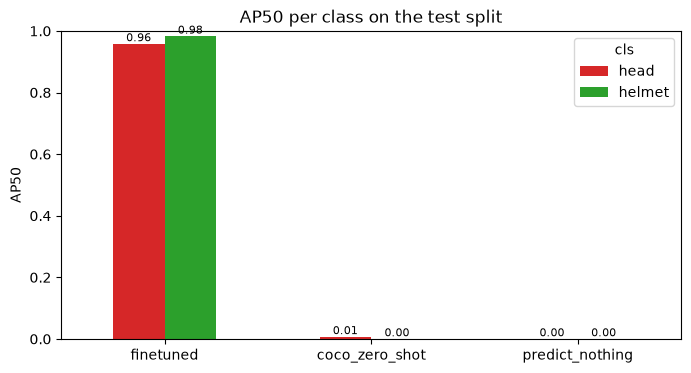

In [18]:
fig, ax = plt.subplots(figsize=(8, 4))
table["AP50"].unstack("cls").loc[list(preds)].plot.bar(ax=ax, rot=0, color=[COLORS[c] for c in CLASS_NAMES])
ax.set(title="AP50 per class on the test split", ylabel="AP50", ylim=(0, 1), xlabel="")
for cont in ax.containers:
    ax.bar_label(cont, fmt="%.2f", fontsize=8)
save_fig(fig, "ap50_per_class")

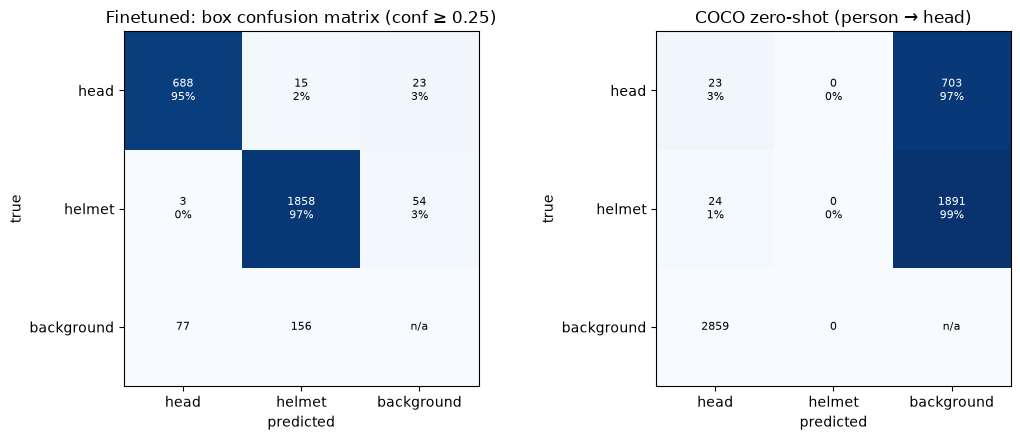

In [19]:
def detection_confusion(p, truth, conf=DET_CONF, iou_thr=0.5):
    """Rows = truth, columns = prediction. 'background' row = predicted box with no
    matching object; 'background' column = object the model missed."""
    labels = CLASS_NAMES + ["background"]
    cm = pd.DataFrame(0, index=labels, columns=labels)
    p = p[p.conf >= conf]
    p_by, g_by = dict(list(p.groupby("image"))), dict(list(truth.groupby("image")))
    for img in set(p_by) | set(g_by):
        d = p_by.get(img, p.iloc[:0]).sort_values("conf", ascending=False)
        g = g_by.get(img, truth.iloc[:0])
        used = np.zeros(len(g), bool)
        ious = iou_matrix(d[BOX].to_numpy(), g[BOX].to_numpy()) if len(d) and len(g) else np.zeros((len(d), 0))
        for (_, pr), iou in zip(d.iterrows(), ious):
            iou = np.where(used, 0.0, iou)
            if len(iou) and iou.max() >= iou_thr:
                j = iou.argmax()
                used[j] = True
                cm.loc[g.cls.iloc[j], pr.cls] += 1
            else:
                cm.loc["background", pr.cls] += 1
        for c in g.cls[~used]:
            cm.loc[c, "background"] += 1
    cm.loc["background", "background"] = 0  # undefined for detection
    return cm


def plot_cm(cm, title, ax, normalise_rows=True):
    """Row-normalised shading with counts. The detection matrix's 'background' row has no
    correct cell, so it is always 100% errors when normalised: it is shown as counts only,
    unshaded, and its corner (nothing predicted on nothing) is marked n/a."""
    shown = cm.div(cm.sum(axis=1).replace(0, 1), axis=0) if normalise_rows else cm.astype(float)
    if "background" in cm.index:
        shown.loc["background"] = 0.0
    ax.imshow(shown, cmap="Blues", vmin=0, vmax=1 if normalise_rows else None)
    ax.set_xticks(range(len(cm.columns)), cm.columns)
    ax.set_yticks(range(len(cm.index)), cm.index)
    ax.set(xlabel="predicted", ylabel="true", title=title)
    for i, row in enumerate(cm.index):
        for j, col in enumerate(cm.columns):
            if row == col == "background":
                txt = "n/a"
            elif normalise_rows and row != "background":
                txt = f"{cm.iat[i, j]}\n{shown.iat[i, j]:.0%}"
            else:
                txt = f"{cm.iat[i, j]}"
            ax.text(j, i, txt, ha="center", va="center", fontsize=8,
                    color="white" if normalise_rows and shown.iat[i, j] > 0.6 else "black")


det_cms = {name: detection_confusion(p, test_gt) for name, p in preds.items()}
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
plot_cm(det_cms["finetuned"], f"Finetuned: box confusion matrix (conf ≥ {DET_CONF})", axes[0])
plot_cm(det_cms["coco_zero_shot"], "COCO zero-shot (person → head)", axes[1])
fig.tight_layout()
save_fig(fig, "confusion_matrix_detection")

### Where it fails

Head recall by object size, the worst missed heads, and the most confident false `head`
boxes.

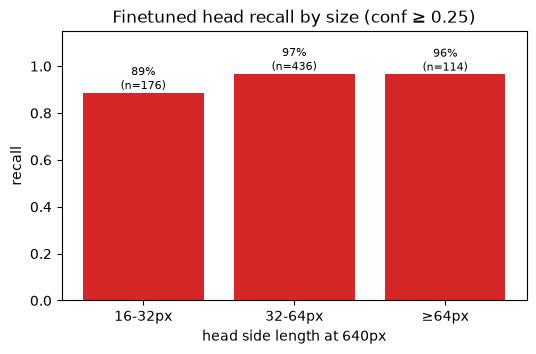

,recall,heads
size,,
<16px,NaN,0
16-32px,0.886,176
32-64px,0.968,436
≥64px,0.965,114


In [20]:
_, head_hits = match_class(preds["finetuned"][preds["finetuned"].conf >= DET_CONF], test_gt, "head")
head_hits["size"] = pd.cut(test_gt[test_gt.cls == "head"].side_px.to_numpy(), [0, 16, 32, 64, np.inf],
                           labels=["<16px", "16-32px", "32-64px", "≥64px"])
by_size = head_hits.groupby("size", observed=False).hit.agg(recall="mean", heads="size")

fig, ax = plt.subplots(figsize=(6, 3.5))
bars = ax.bar(by_size.index.astype(str), by_size.recall, color=COLORS["head"])
ax.bar_label(bars, labels=[f"{r:.0%}\n(n={n})" for r, n in zip(by_size.recall, by_size.heads)], fontsize=8)
ax.set(title=f"Finetuned head recall by size (conf ≥ {DET_CONF})", ylabel="recall", ylim=(0, 1.15),
       xlabel=f"head side length at {IMGSZ}px")
save_fig(fig, "failure_recall_by_size")
display(by_size)

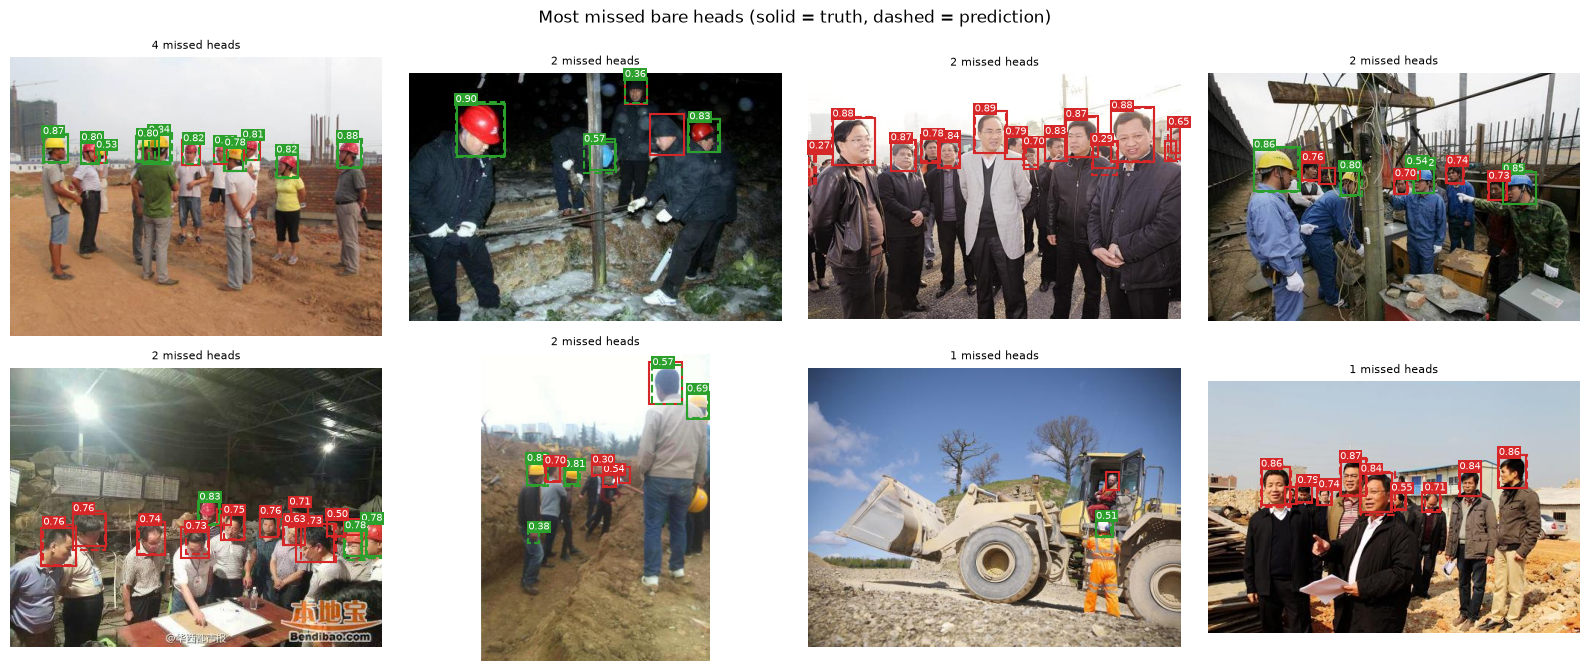

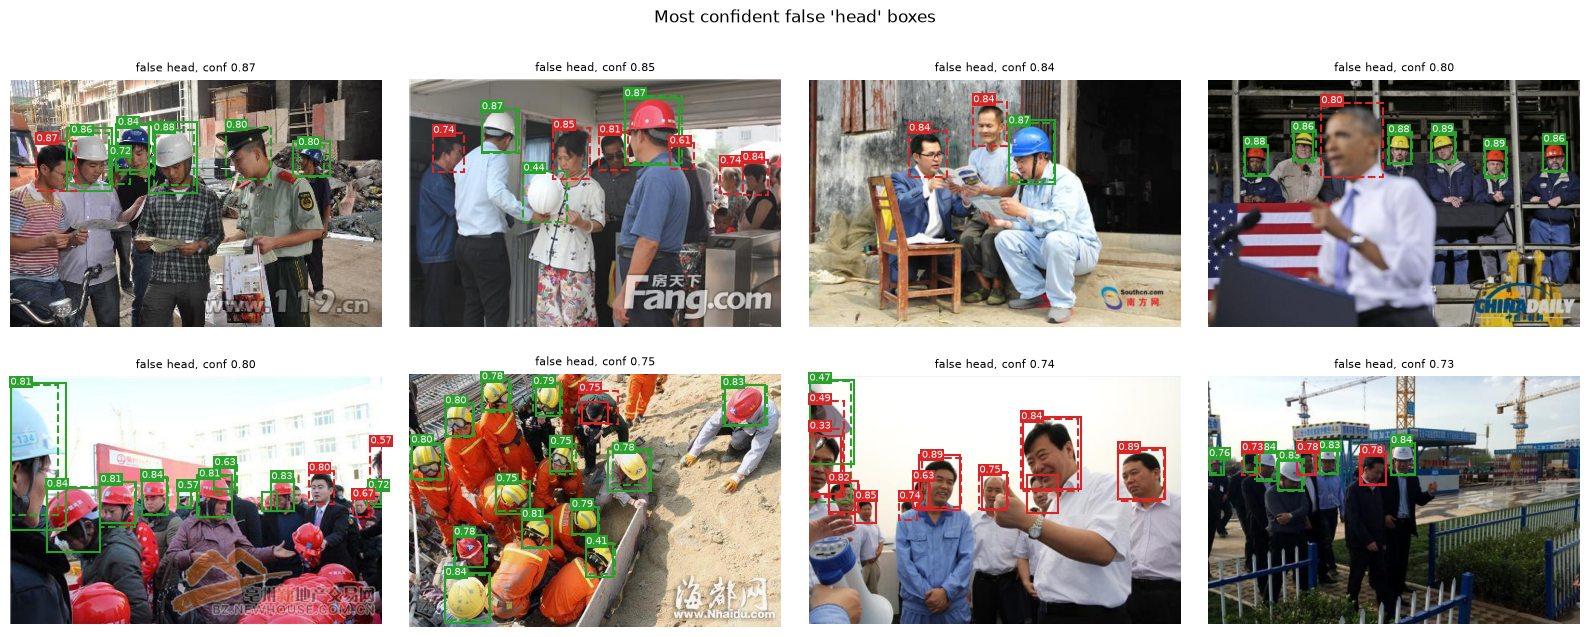

In [21]:
ft = preds["finetuned"][preds["finetuned"].conf >= DET_CONF]
missed = head_hits[~head_hits.hit].groupby("image").size().sort_values(ascending=False)
grid(test_imgs.set_index("image").loc[missed.index[:8]].reset_index(),
     "Most missed bare heads (solid = truth, dashed = prediction)", "failure_missed_heads",
     truth=test_gt, preds=ft, titles=[f"{n} missed heads" for n in missed.values[:8]])

ft_matched, _ = match_class(ft, test_gt, "head")
false_heads = ft_matched[~ft_matched.tp].sort_values("conf", ascending=False).drop_duplicates("image")
grid(test_imgs.set_index("image").loc[false_heads.image[:8]].reset_index(),
     "Most confident false 'head' boxes", "failure_false_heads", truth=test_gt, preds=ft,
     titles=[f"false head, conf {c:.2f}" for c in false_heads.conf[:8]])

## 5. Optimising the cost

In this analysis one case is one image which is equivalent to one camera frame. Its score is the highest head confidence in it. The case is flagged when that score is ≥ the threshold. 

The test split has about 20% positive images as showed in the division above. 

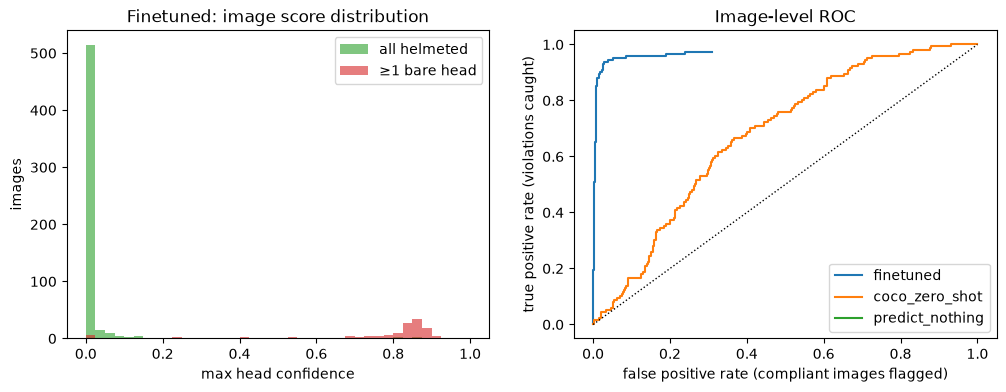

In [22]:
y_true = test_imgs.has_head.to_numpy()


def image_scores(p):
    """Highest head confidence per test image; 0 when the model drew no head box at all."""
    best = p[p.cls == POSITIVE].groupby("image").conf.max()
    return test_imgs.image.map(best).fillna(0.0).to_numpy()


def flagged(s, thr):
    """A snapshot is flagged when its best head box reaches the threshold. An image without
    any head box is never flagged, so 'predict nothing' always passes everything."""
    return (s > 0) & (s >= thr)


scores = {name: image_scores(p) for name, p in preds.items()}
pd.DataFrame({"image": test_imgs.image, "has_head": y_true, "n_head": test_imgs.n_head,
              **{f"score_{k}": v for k, v in scores.items()}}).to_csv(OUT_DIR / "test_image_scores.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
bins = np.linspace(0, 1, 41)
axes[0].hist(scores["finetuned"][~y_true], bins=bins, alpha=0.6, label="all helmeted", color="tab:green")
axes[0].hist(scores["finetuned"][y_true], bins=bins, alpha=0.6, label="≥1 bare head", color="tab:red")
axes[0].set(title="Finetuned: image score distribution", xlabel="max head confidence", ylabel="images")
axes[0].legend()

for name, s in scores.items():
    thr = np.unique(np.concatenate([[0, 1.01], s]))
    tpr = [flagged(s[y_true], t).mean() for t in thr]
    fpr = [flagged(s[~y_true], t).mean() for t in thr]
    axes[1].plot(fpr, tpr, label=name)
axes[1].plot([0, 1], [0, 1], "k:", lw=1)
axes[1].set(title="Image-level ROC", xlabel="false positive rate (compliant images flagged)",
            ylabel="true positive rate (violations caught)")
axes[1].legend()
save_fig(fig, "image_level_scores")

### Cost matrix and base rate

For this i made some assumptions that are explained better inthe report but basicually 

- The Hourly cost of the employee that has to check the image if it is flaged is 23 euros and it takes him 5 minutes to check it 
- These assumptions mean an incorrect flag (false positive) have a very low cost of around 2 euros
- A false negative means a violation could be missed. We assume an injury could cost around 200k because of leave days, coverage, hospital etc and that there is 1/1,000 chance of an injury if the helment is not on. Hence the cost of missing a bare head, in other words of a false negative is 200.
- We also assume that in reality the share of real site snapshots with bare heads will be lower than represented inthe dataset with aorund 5% only


In [23]:
# Safety technician: ~€30k gross/yr + ~32% employer social security ≈ €40k / ~1,750 h ≈ €23/h
CHECK_MINUTES = 5
HOURLY_COST = 23.0
CHECK_COST = round(CHECK_MINUTES / 60 * HOURLY_COST)  # ≈ €2

COST = {
    "FP": CHECK_COST,  # compliant snapshot flagged: one wasted check
    "TP": CHECK_COST,  # violation caught: the same check
    "TN": 0.0,         # compliant snapshot passed: nothing happens
    "FN": 200.0,       # violation missed: 100x a false alarm (≈ 1-in-1,000 chance of a €200k head injury)
}
BASE_RATE = 0.05  # assumed share of real-site snapshots with ≥1 bare head (dataset has ~20%)
THRESHOLDS = np.round(np.arange(0, 1.0001, 0.01), 2)


def rates(s, thr):
    """(catch rate, false-alarm rate) on the test split at a threshold."""
    return flagged(s[y_true], thr).mean(), flagged(s[~y_true], thr).mean()


def cost_per_1000(tpr, fpr, base_rate=BASE_RATE, cost=COST):
    pos = base_rate * (tpr * cost["TP"] + (1 - tpr) * cost["FN"])
    neg = (1 - base_rate) * (fpr * cost["FP"] + (1 - fpr) * cost["TN"])
    return 1000 * (pos + neg)


rows = []
for name, s in scores.items():
    for t in THRESHOLDS:
        tpr, fpr = rates(s, t)
        rows.append(dict(model=name, threshold=t, tpr=tpr, fpr=fpr,
                         flagged_share=BASE_RATE * tpr + (1 - BASE_RATE) * fpr,
                         cost_per_1000=cost_per_1000(tpr, fpr)))
sweep = pd.DataFrame(rows)
sweep.to_csv(OUT_DIR / "cost_sweep.csv", index=False)

ft_sweep = sweep[sweep.model == "finetuned"].set_index("threshold")
best_thr = ft_sweep.cost_per_1000.idxmin()
references = {
    "pass everything (no model)": cost_per_1000(0, 0),
    "flag everything (person checks all)": cost_per_1000(1, 1),
}
display(pd.Series({**references,
                   **{f"{m} at its best threshold": sweep[sweep.model == m].cost_per_1000.min() for m in scores}},
                  name="cost per 1,000 cases (€)"))
print(f"Finetuned minimum-cost threshold: {best_thr:.2f}")

pass everything (no model)               10000.000
flag everything (person checks all)       2000.000
finetuned at its best threshold            699.064
coco_zero_shot at its best threshold      1849.160
predict_nothing at its best threshold    10000.000
Name: cost per 1,000 cases (€), dtype: float64

Finetuned minimum-cost threshold: 0.07


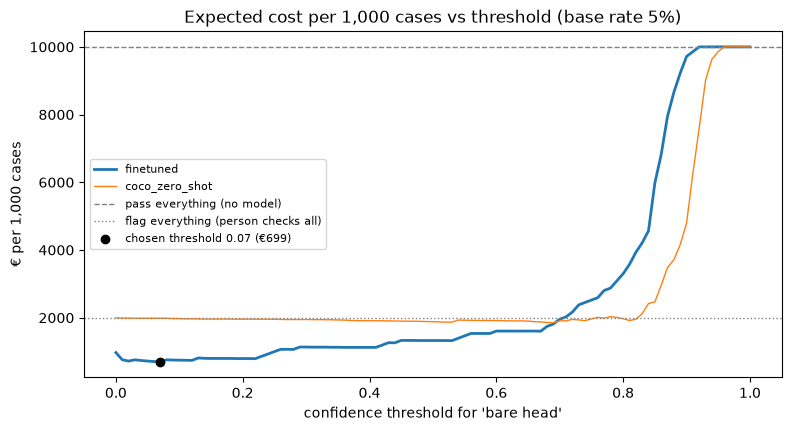

In [24]:
fig, ax = plt.subplots(figsize=(9, 4.5))
for name in ["finetuned", "coco_zero_shot"]:
    d = sweep[sweep.model == name]
    ax.plot(d.threshold, d.cost_per_1000, label=name, lw=2 if name == "finetuned" else 1)
for (label, v), ls in zip(references.items(), ["--", ":"]):
    ax.axhline(v, color="grey", ls=ls, lw=1, label=label)
ax.scatter([best_thr], [ft_sweep.cost_per_1000[best_thr]], color="k", zorder=5,
           label=f"chosen threshold {best_thr:.2f} (€{ft_sweep.cost_per_1000[best_thr]:,.0f})")
ax.set(title=f"Expected cost per 1,000 cases vs threshold (base rate {BASE_RATE:.0%})",
       xlabel="confidence threshold for 'bare head'", ylabel="€ per 1,000 cases")
ax.legend(fontsize=8)
save_fig(fig, "cost_vs_threshold")

This plots how much the system costs based on the predictions of each model per per 1,000 snapshots for every possible threshold. The idea here is to choose the one that is the choopest which is super low at 0.07. This is due to the huge difference in cost of false positive vs false negative. The model cares more about being strict and overclassifying wrong bare heads. 

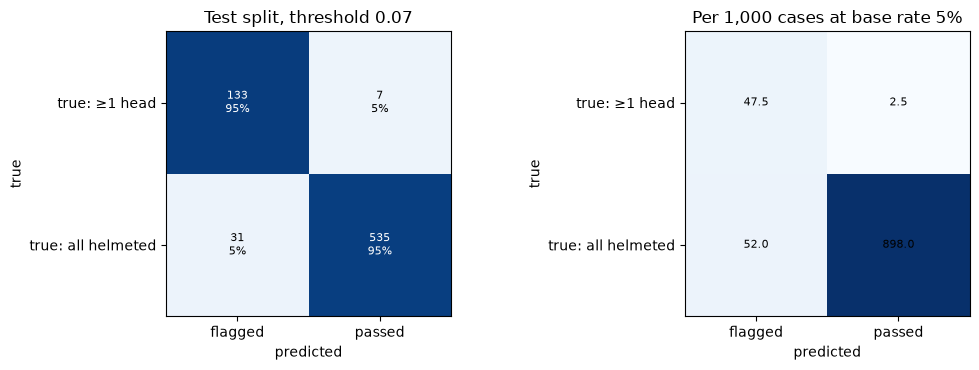

In [25]:
def image_confusion(s, thr):
    pred = flagged(s, thr)
    return pd.DataFrame([[(y_true & pred).sum(), (y_true & ~pred).sum()],
                         [(~y_true & pred).sum(), (~y_true & ~pred).sum()]],
                        index=["true: ≥1 head", "true: all helmeted"],
                        columns=["flagged", "passed"])


cm_img = image_confusion(scores["finetuned"], best_thr)
tpr, fpr = rates(scores["finetuned"], best_thr)
cm_1000 = pd.DataFrame([[1000 * BASE_RATE * tpr, 1000 * BASE_RATE * (1 - tpr)],
                        [1000 * (1 - BASE_RATE) * fpr, 1000 * (1 - BASE_RATE) * (1 - fpr)]],
                       index=cm_img.index, columns=cm_img.columns).round(1)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
plot_cm(cm_img, f"Test split, threshold {best_thr:.2f}", axes[0])
plot_cm(cm_1000, f"Per 1,000 cases at base rate {BASE_RATE:.0%}", axes[1], normalise_rows=False)
fig.tight_layout()
save_fig(fig, "confusion_matrix_image_level")

Box-level precision and recall at the cost-chosen threshold, next to the conventional 0.25 used in section 4. AP does not depend on a threshold, so it is not repeated.

In [26]:
def pr_at(p, conf):
    rows = {}
    for c in CLASS_NAMES:
        m, g = match_class(p[p.conf >= conf], test_gt, c)
        rows[c] = {"precision": m.tp.mean() if len(m) else np.nan, "recall": g.hit.mean()}
    return pd.DataFrame(rows).T


at_threshold_parts = {f"conf ≥ {DET_CONF}": pr_at(preds["finetuned"], DET_CONF),
                      f"conf ≥ {best_thr:.2f} (cost-chosen)": pr_at(preds["finetuned"], best_thr)}
at_threshold = pd.concat(at_threshold_parts, axis=1)
at_threshold.to_csv(OUT_DIR / "per_class_at_threshold.csv")
display(at_threshold)

conf ≥ 0.25        conf ≥ 0.07 (cost-chosen)       
         precision recall                 precision recall
head         0.896  0.948                     0.803  0.963
helmet       0.916  0.971                     0.835  0.980

### Sensitivity of the chosen threshold

The idea is to study how the minimum-cost threshold moves when the FN:FP cost ratio and the base rate change. If the base rate wa shigher than 5% and there was a factory with more violations maybe the best threshold would be different. This is all to be able to later show it in the dashboard

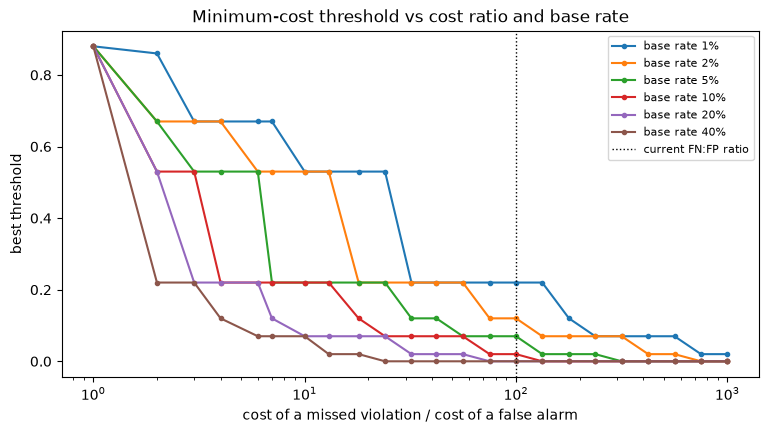

In [27]:
def best_threshold(base_rate, cost):
    c = [cost_per_1000(*rates(scores["finetuned"], t), base_rate, cost) for t in THRESHOLDS]
    return THRESHOLDS[int(np.argmin(c))], min(c)


ratios = np.unique(np.round(np.logspace(0, 3, 25)))
base_rates = [0.01, 0.02, 0.05, 0.1, 0.2, 0.4]
sens = pd.DataFrame([dict(ratio=r, base_rate=b, threshold=best_threshold(b, {**COST, "FN": COST["FP"] * r})[0])
                     for r in ratios for b in base_rates])
sens.to_csv(OUT_DIR / "threshold_sensitivity.csv", index=False)

fig, ax = plt.subplots(figsize=(9, 4.5))
for b, d in sens.groupby("base_rate"):
    ax.plot(d.ratio, d.threshold, marker=".", label=f"base rate {b:.0%}")
ax.axvline(COST["FN"] / COST["FP"], color="k", ls=":", lw=1, label="current FN:FP ratio")
ax.set(xscale="log", title="Minimum-cost threshold vs cost ratio and base rate",
       xlabel="cost of a missed violation / cost of a false alarm", ylabel="best threshold")
ax.legend(fontsize=8)
save_fig(fig, "threshold_sensitivity")

## 6. Pass, review or fail (README step 7)

Two thresholds split the image score into three outcomes:

| Outcome | Score | What happens | Cost if ≥1 bare head | Cost if all helmeted |
|---|---|---|---|---|
| **Pass** | below `low` | nobody looks | FN (€200) | TN (€0) |
| **Review** | `low` to `high` | the officer looks at the photo, walks over only if it is real | review + TP, or review + FN if the reviewer misses it | review |
| **Fail** | `high` and above | the officer is sent straight away | TP (€2) | FP (€2) |

The reviewer misses a share of the real violations they look at (`REVIEWER_MISS_RATE`) and
never raises a false alarm. Step 5's single threshold is the special case `low = high`, where
nothing goes to review.

In [ ]:
# Operating assumptions for step 7 (justified in REPORT.md)
CAMERAS = 1
SNAPSHOT_EVERY_MIN = 5
WORK_HOURS = 8
CASES_PER_DAY = CAMERAS * (60 / SNAPSHOT_EVERY_MIN) * WORK_HOURS  # 96 snapshots a day

REVIEW_MINUTES = 1  # looking at one flagged photo on a screen
REVIEW_COST = CHECK_COST * REVIEW_MINUTES / CHECK_MINUTES  # priced at the step 5 rate: €2 per 5 min → €0.40
REVIEWER_MISS_RATE = 0.01  # share of real violations a reviewer overlooks

NO_AUTO_FAIL = 1.01  # a high threshold above any score: everything above low goes to review
band_grid = np.append(THRESHOLDS, NO_AUTO_FAIL)
s_ft = scores["finetuned"]
F_pos = np.array([flagged(s_ft[y_true], t).mean() for t in band_grid])  # share of violations above t
F_neg = np.array([flagged(s_ft[~y_true], t).mean() for t in band_grid])  # share of compliant above t


def shares(F, lo, hi):
    """(pass, review, fail) shares for thresholds at grid positions lo <= hi."""
    return 1 - F[lo], F[lo] - F[hi], F[hi]


def per_case_cost(pos, neg, base_rate=BASE_RATE, miss=REVIEWER_MISS_RATE):
    (pp, pr, pf), (np_, nr, nf) = pos, neg
    reviewed_pos = REVIEW_COST + (1 - miss) * COST["TP"] + miss * COST["FN"]
    pos_cost = pp * COST["FN"] + pr * reviewed_pos + pf * COST["TP"]
    neg_cost = np_ * COST["TN"] + nr * (REVIEW_COST + COST["TN"]) + nf * COST["FP"]
    return base_rate * pos_cost + (1 - base_rate) * neg_cost


LO, HI = np.meshgrid(np.arange(len(band_grid)), np.arange(len(band_grid)), indexing="ij")


def cheapest_band(miss=REVIEWER_MISS_RATE):
    cost = 1000 * per_case_cost(shares(F_pos, LO, HI), shares(F_neg, LO, HI), miss=miss)
    cost = np.where(HI >= LO, cost, np.nan)
    return cost, np.unravel_index(np.nanargmin(cost), cost.shape)


band_cost, (lo_i, hi_i) = cheapest_band()
LOW_THR, HIGH_THR = float(band_grid[lo_i]), float(band_grid[hi_i])
print(f"cheapest band: pass < {LOW_THR:.2f} ≤ review < {HIGH_THR:.2f} ≤ fail  "
      f"(€{band_cost[lo_i, hi_i]:,.0f} per 1,000 snapshots)")

cheapest band: pass < 0.00 ≤ review < 0.53 ≤ fail  (€528 per 1,000 snapshots)


In [ ]:
def design(name, pos, neg):
    """Daily cost and workload of one way of running the site, for CASES_PER_DAY snapshots."""
    (pp, pr, pf), (np_, nr, nf) = pos, neg
    per_case = per_case_cost(pos, neg)
    reviews = CASES_PER_DAY * (BASE_RATE * pr + (1 - BASE_RATE) * nr)
    # walk over only for violations: auto-failed ones, and reviewed ones the reviewer catches
    walks = CASES_PER_DAY * (BASE_RATE * ((1 - REVIEWER_MISS_RATE) * pr + pf) + (1 - BASE_RATE) * nf)
    minutes = reviews * REVIEW_MINUTES + walks * CHECK_MINUTES
    missed = CASES_PER_DAY * BASE_RATE * (pp + REVIEWER_MISS_RATE * pr)
    return {"design": name, "€ per 1,000": 1000 * per_case, "€ per day": CASES_PER_DAY * per_case,
            "missed per day": missed, "reviews per day": reviews,
            "walks per day": walks, "person-min per day": minutes,
            "people needed": minutes / (WORK_HOURS * 60)}


step5_i = int(np.where(band_grid == best_thr)[0][0])
designs = pd.DataFrame([
    design("do nothing", (1, 0, 0), (1, 0, 0)),
    design("person reviews every snapshot", (0, 1, 0), (0, 1, 0)),
    design(f"model alone (fail ≥ {best_thr:.2f})", shares(F_pos, step5_i, step5_i), shares(F_neg, step5_i, step5_i)),
    design(f"model + review band [{LOW_THR:.2f}, {HIGH_THR:.2f})", shares(F_pos, lo_i, hi_i), shares(F_neg, lo_i, hi_i)),
]).set_index("design")
designs.to_csv(OUT_DIR / "designs_per_day.csv")
print(f"{CAMERAS} camera, one snapshot every {SNAPSHOT_EVERY_MIN} min, {WORK_HOURS} h day "
      f"= {CASES_PER_DAY:.0f} snapshots a day; base rate {BASE_RATE:.0%}; "
      f"review {REVIEW_MINUTES} min (€{REVIEW_COST:.2f}); reviewer misses {REVIEWER_MISS_RATE:.0%}")
display(designs.round(2))

outcome = np.select([flagged(s_ft, HIGH_THR), flagged(s_ft, LOW_THR)], ["fail", "review"], "pass")
band_cm = pd.crosstab(pd.Series(np.where(y_true, "true: ≥1 head", "true: all helmeted"), name="truth"),
                      pd.Series(outcome, name="outcome")).reindex(columns=["pass", "review", "fail"], fill_value=0)
print("Test split at the chosen band:")
display(band_cm)

1 camera, one snapshot every 5 min, 8 h day = 96 snapshots a day; base rate 5%; review 1 min (€0.40); reviewer misses 1%


,"€ per 1,000",€ per day,missed per day,reviews per day,walks per day,person-min per day,people needed
design,,,,,,,
do nothing,10000.00,960.00,4.80,0.00,0.00,0.00,0.00
person reviews every snapshot,599.00,57.50,0.05,96.00,4.75,119.76,0.25
model alone (fail ≥ 0.07),699.06,67.11,0.24,0.00,9.56,47.78,0.10
"model + review band [0.00, 0.53)",527.51,50.64,0.14,27.68,5.63,55.80,0.12


Test split at the chosen band:


outcome,pass,review,fail
truth,,,
true: all helmeted,391,169,6
true: ≥1 head,4,13,123


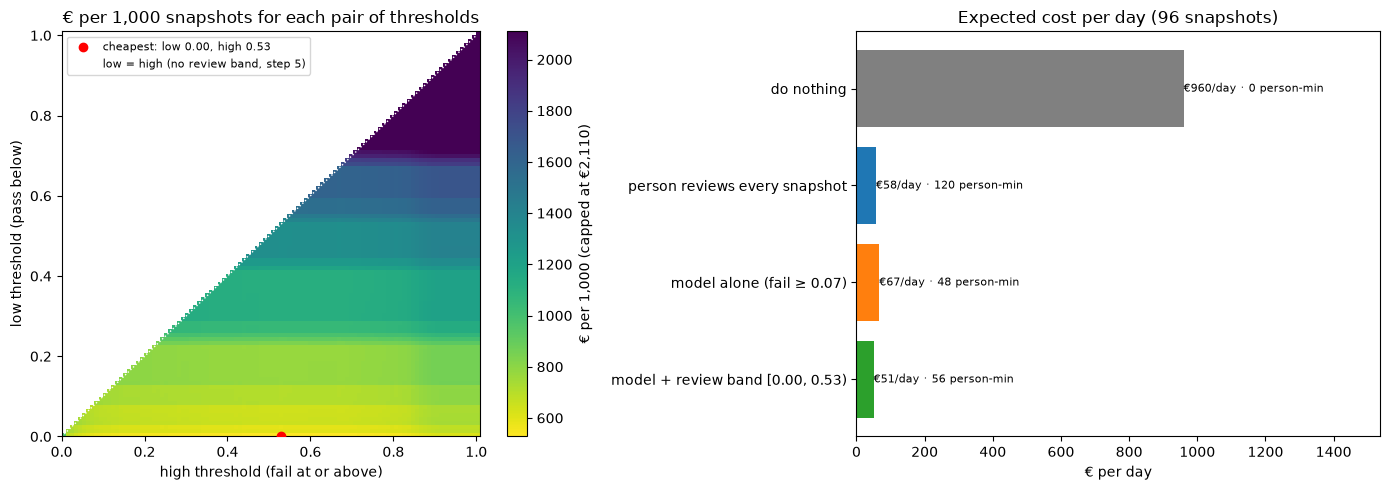

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

vmax = np.nanmin(band_cost) * 4
im = axes[0].imshow(band_cost, origin="lower", cmap="viridis_r", vmax=vmax,
                    extent=[0, NO_AUTO_FAIL, 0, NO_AUTO_FAIL], aspect="auto")
axes[0].scatter([HIGH_THR], [LOW_THR], color="red", zorder=5,
                label=f"cheapest: low {LOW_THR:.2f}, high {HIGH_THR:.2f}")
axes[0].plot([0, 1], [0, 1], "w:", lw=1, label="low = high (no review band, step 5)")
axes[0].set(title="€ per 1,000 snapshots for each pair of thresholds", xlabel="high threshold (fail at or above)",
            ylabel="low threshold (pass below)")
axes[0].legend(fontsize=8, loc="upper left")
fig.colorbar(im, ax=axes[0], label=f"€ per 1,000 (capped at €{vmax:,.0f})")

bars = axes[1].barh(designs.index, designs["€ per day"], color=["grey", "tab:blue", "tab:orange", "tab:green"])
axes[1].bar_label(bars, labels=[f"€{c:,.0f}/day · {m:.0f} person-min" for c, m in
                                zip(designs["€ per day"], designs["person-min per day"])], fontsize=8)
axes[1].invert_yaxis()
axes[1].set(title=f"Expected cost per day ({CASES_PER_DAY:.0f} snapshots)", xlabel="€ per day",
            xlim=(0, designs["€ per day"].max() * 1.6))
fig.tight_layout()
save_fig(fig, "review_band")

review_band = {
    "low": LOW_THR, "high": HIGH_THR, "review_cost": REVIEW_COST, "review_minutes": REVIEW_MINUTES,
    "reviewer_miss_rate": REVIEWER_MISS_RATE, "check_minutes": CHECK_MINUTES, "hourly_cost": HOURLY_COST,
    "cases_per_day": CASES_PER_DAY, "cameras": CAMERAS, "snapshot_every_min": SNAPSHOT_EVERY_MIN,
    "work_hours": WORK_HOURS, "cost_per_1000": float(band_cost[lo_i, hi_i]),
    "designs": designs.to_dict(orient="index"),
}

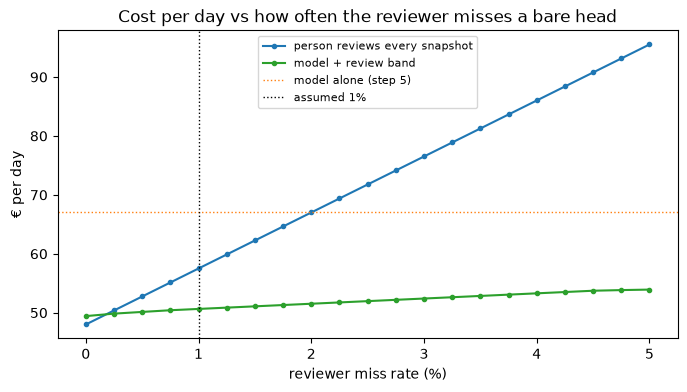

model + review band becomes cheaper than reviewing everything from a miss rate of about 0.25%


In [ ]:
# How the comparison moves with the reviewer miss rate (the band is re-optimised at each rate)
miss_rates = np.round(np.arange(0, 0.0501, 0.0025), 4)
rows = []
for m in miss_rates:
    cost, (i, j) = cheapest_band(m)
    review_all = per_case_cost((0, 1, 0), (0, 1, 0), miss=m)
    rows.append({"miss_rate": m, "model + review band": CASES_PER_DAY * cost[i, j] / 1000,
                 "person reviews every snapshot": CASES_PER_DAY * review_all,
                 "low": band_grid[i], "high": band_grid[j]})
miss_sens = pd.DataFrame(rows).set_index("miss_rate")
miss_sens.to_csv(OUT_DIR / "reviewer_miss_sensitivity.csv")
model_alone_day = designs.loc[designs.index.str.startswith("model alone"), "€ per day"].iloc[0]
cheaper = miss_sens["model + review band"] < miss_sens["person reviews every snapshot"]
break_even = miss_sens.index[cheaper.to_numpy().argmax()] if cheaper.any() else None

fig, ax = plt.subplots(figsize=(8, 4))
for col, color in [("person reviews every snapshot", "tab:blue"), ("model + review band", "tab:green")]:
    ax.plot(miss_sens.index * 100, miss_sens[col], marker=".", label=col, color=color)
ax.axhline(model_alone_day, color="tab:orange", ls=":", lw=1, label="model alone (step 5)")
ax.axvline(REVIEWER_MISS_RATE * 100, color="k", ls=":", lw=1, label=f"assumed {REVIEWER_MISS_RATE:.0%}")
ax.set(title="Cost per day vs how often the reviewer misses a bare head",
       xlabel="reviewer miss rate (%)", ylabel="€ per day")
ax.legend(fontsize=8)
save_fig(fig, "reviewer_miss_sensitivity")
print(f"model + review band becomes cheaper than reviewing everything from a miss rate of about "
      f"{break_even:.2%}" if break_even is not None else "reviewing everything stays cheaper up to 5%")

## 7. Save what the app needs

In [31]:
save_json({
    "dataset": {"workspace": RF_WORKSPACE, "project": RF_PROJECT, "version": RF_VERSION},
    "weights": str(WEIGHTS.relative_to(ROOT)),
    "positive_class": POSITIVE,
    "class_names": CLASS_NAMES,
    "imgsz": IMGSZ,
    "det_conf": DET_CONF,
    "cost": COST,
    "base_rate": BASE_RATE,
    "threshold": float(best_thr),
    "cost_per_1000_at_threshold": float(ft_sweep.cost_per_1000[best_thr]),
    "references_per_1000": references,
    "overall": overall.to_dict(orient="index"),
    "detection_confusion": {k: v.to_dict() for k, v in det_cms.items()},
    "per_class_at_threshold": {k: v.to_dict(orient="index") for k, v in at_threshold_parts.items()},
    "review_band": review_band,
}, "operating_point.json")
print(sorted(p.name for p in OUT_DIR.iterdir()))

['cost_sweep.csv', 'dataset_summary.csv', 'designs_per_day.csv', 'figures', 'operating_point.json', 'per_class_at_threshold.csv', 'per_class_metrics.csv', 'test_image_scores.csv', 'threshold_sensitivity.csv', 'training_config.json']


### Colab only: bundle the results

Zips the trained weights and `outputs/` so they can be copied back into the local repo and
committed. Does nothing locally.

In [32]:
if IN_COLAB:
    bundle = Path("/content/hardhat_results.zip")
    subprocess.run(["zip", "-qr", str(bundle), WEIGHTS.relative_to(ROOT), OUT_DIR.relative_to(ROOT)],
                   cwd=ROOT, check=True)
    print(f"bundle: {bundle} ({bundle.stat().st_size / 1e6:.1f} MB)")
    try:
        from google.colab import files
        files.download(str(bundle))
    except Exception as e:  # the VS Code extension may not support browser downloads
        print(f"automatic download unavailable ({e}); fetch {bundle} from the Colab file browser")